In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [22]:
data = pd.read_csv("./exam_scores.csv")
x = data["Hours"].values
y_actual = data["Score"].values


def compute_cost(x, y, w, b):
    m = len(x)
    y_predicted = w * x + b
    cost = np.sum((y_predicted - y) ** 2) / (2 * m)
    return cost



w = 0
b = 0
j = compute_cost(x, y_actual, w, b)
print("Initial Cost J:", j)

Initial Cost J: 2153.7894736842104


In [30]:
import numpy as np

# Ensure inputs are NumPy arrays for safe integer indexing
x = data['Hours'].values
y_actual = data['Score'].values
m = len(data)

def compute_gradient(x, y_actual, m, w, b):
    dj_dw = 0.0
    dj_db = 0.0

    for i in range(m):
        prediction = w * x[i] + b
        error = prediction - y_actual[i]

        dj_dw += error * x[i]
        dj_db += error

    dj_dw /= m
    dj_db /= m

    return dj_dw, dj_db


# Lowered learning rate to prevent exploding to NaN
learning_rate = 0.001  

# Tighter convergence threshold
tolerance = 1e-5  

w = 0.0
b = 0.0
cnt = 0

while cnt < 1000:
    dj_dw, dj_db = compute_gradient(x, y_actual, m, w, b)

    temp_w = w - learning_rate * dj_dw
    temp_b = b - learning_rate * dj_db

    # Safety check: stop if values explode
    if np.isnan(temp_w) or np.isnan(temp_b):
        print(f"Diverged at iteration {cnt}! Try lowering the learning rate.")
        break

    # Convergence check
    if abs(temp_w - w) < tolerance and abs(temp_b - b) < tolerance:
        print(f"Converged at iteration {cnt}")
        break

    w = temp_w
    b = temp_b
    cnt += 1

print(f"Final parameters: w = {w:.4f}, b = {b:.4f}")


Final parameters: w = 10.3010, b = 2.5375


<>:25: SyntaxWarning: invalid escape sequence '\h'
<>:25: SyntaxWarning: invalid escape sequence '\h'
C:\Users\ansha\AppData\Local\Temp\ipykernel_22820\3745109965.py:25: SyntaxWarning: invalid escape sequence '\h'
  label=f"Model Fit: $\hat{{y}} = {w:.2f}x + {b:.2f}$",


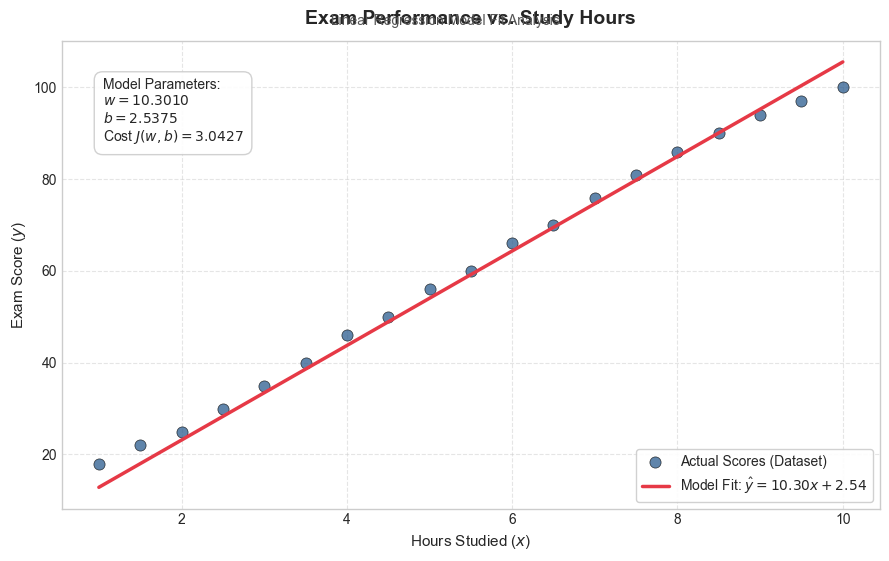

In [31]:
y_now = w * x + b
cost_J = np.mean((y_now - y_actual) ** 2) / 2

# Set plot style and figure dimensions
plt.figure(figsize=(9, 6), dpi=100)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

# 1. Plot actual data points
plt.scatter(
    x, y_actual,
    color="#2b5c8f",
    s=65,
    alpha=0.75,
    edgecolors="black",
    linewidth=0.5,
    label="Actual Scores (Dataset)",
    zorder=3
)

# 2. Plot fitted regression line
plt.plot(
    x, y_now,
    color="#e63946",
    linewidth=2.5,
    label=f"Model Fit: $\hat{{y}} = {w:.2f}x + {b:.2f}$",
    zorder=4
)

# 3. Add annotated text box with parameter summary
text_str = f"Model Parameters:\n$w = {w:.4f}$\n$b = {b:.4f}$\nCost $J(w,b) = {cost_J:.4f}$"
props = dict(boxstyle="round,pad=0.6", facecolor="white", alpha=0.9, edgecolor="#cccccc")
plt.gca().text(
    0.05, 0.92, text_str,
    transform=plt.gca().transAxes,
    fontsize=10,
    verticalalignment="top",
    bbox=props
)

# 4. Labels, titles, and grid customization
plt.title("Exam Performance vs. Study Hours", fontsize=14, fontweight="bold", pad=12)
plt.suptitle("Linear Regression Model Fit Analysis", fontsize=10, color="#555555", y=0.92)

plt.xlabel("Hours Studied ($x$)", fontsize=11, fontweight="medium")
plt.ylabel("Exam Score ($y$)", fontsize=11, fontweight="medium")

# Improve grid & legend aesthetics
plt.grid(True, linestyle="--", alpha=0.5, zorder=1)
plt.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9, fontsize=10)

# Clean borders and layout
plt.tight_layout()
plt.show()
